## HuggingFace Transformers: API, Models and Fine-Tuning Techniques

### Day 3

#### Environment (Huggingface Transformers 4.x)

```bash
   conda create -n hf4_env python=3.11 jupyter -y
   conda activate hf4_env
   conda install -c conda-forge "transformers>=4.40,<5.0" \
                    datasets evaluate accelerate          \
                    pytorch torchvision torchaudio -y
   pip install dotenv
   pip install torch # Might be required for some setups
   pip install matplotlib
   pip install protobuf
   pip install scikit-learn
   # pip install seaborn # Uncomment if you prefer seaborn's heatmaps over sklearn's ConfusionMatrixDisplay
   
```

In [1]:
import sys
import torch
import transformers
import PIL

print("Python version:", sys.version)
print("Torch version:", torch.__version__)
print("Transformers version:", transformers.__version__)
print("PIL version:", PIL.__version__)

Python version: 3.11.14 | packaged by conda-forge | (main, Oct 13 2025, 14:29:50) [Clang 19.1.7 ]
Torch version: 2.10.0
Transformers version: 4.57.6
PIL version: 12.3.0


In [ ]:
import torch


In [ ]:
torch.cuda.

##### Image Segmentation using Vision Transformers (ViT)

In [ ]:
from PIL import Image
import requests

print("Fetching image...")
url = "https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/transformers/tasks/segmentation_input.jpg"
image = Image.open(requests.get(url, stream=True).raw)
print("Image fetched successfully.")
image

In [ ]:
print(type(image))

In [ ]:
from transformers import pipeline
semantic_segmentation = pipeline("image-segmentation", 
                                 "nvidia/segformer-b1-finetuned-cityscapes-1024-1024",
                                 use_fast=True)

results = semantic_segmentation(image)
results

In [ ]:
results[-1]

In [ ]:
results[-1]["mask"]

In [ ]:
Image.composite(image, results[-1]["mask"], results[-1]["mask"])

--- 

##### Image Classification using Vision Transformers (ViT)

In [ ]:
!pip install matplotlib

In [ ]:
from transformers import pipeline
from PIL import Image
import requests

import matplotlib.pyplot as plt

# Load image classification pipeline
classifier = pipeline(
    "image-classification",
    model="google/vit-base-patch16-224",
    use_fast=True
)

# Load a sample image
url = "https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/pipeline-cat-chonk.jpeg"
response = requests.get(url, stream=True).raw
image = Image.open(response)

image

In [ ]:

# Classify
results = classifier(image)
for result in results[:5]:
    print(f"{result['label']}: {result['score']:.3f}")


In [ ]:
image = Image.open("../../tulip2.jpeg")
image

In [ ]:
results = classifier(image)
for result in results[:5]:
    print(f"{result['label']}: {result['score']:.3f}")

In [ ]:

print("---")
# Try with your own images
image = Image.open("../../tulip2.jpeg")
results = classifier(image)
for result in results[:5]:
    print(f"{result['label']}: {result['score']:.3f}")

---

#### Image Enhancement

In [ ]:
from PIL import Image
import requests

url = "https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/transformers/tasks/cat.jpg"
image = Image.open(requests.get(url, stream=True).raw)

print(image.size)
image

In [ ]:
from transformers import pipeline
pipe = pipeline(task="image-to-image", model="caidas/swin2SR-lightweight-x2-64")

upscaled = pipe(image)
print(upscaled.size)
upscaled

In [ ]:
upscaled = pipe(upscaled)
print(upscaled.size)
upscaled

---

### Text-to-Text Generation

In [ ]:
from transformers import pipeline

grammar_pipeline = pipeline(
    "text2text-generation",
    model="t5-base")

incorrect_text = "He have been working here since five years."
input_text = f"correct grammar: {incorrect_text}"
result = grammar_pipeline(input_text, num_beams=5)

print("Original:", incorrect_text)
print("Corrected:", result[0]['generated_text'])

In [ ]:
!pip install protobuf

In [1]:
from transformers import pipeline

# 1. Initialize the text2text-generation pipeline with a dedicated grammar model
grammar_pipeline = pipeline(
    "text2text-generation", 
    model="AventIQ-AI/t5-small-grammar-correction"
)

# Other models you can try:
# - AventIQ-AI/t5-base-grammar-correction
# - vennify/t5-base-grammar-correction
# - pszemraj/flan-t5-large-grammar-synthesis
# - Sajid030/t5-base-grammar-synthesis

# 2. Define the grammatically incorrect text
# Note: T5 models usually expect a task prefix like "correct grammar: "
incorrect_text = "She dont like to eat vegetables but she like fruits."
input_text = f"correct grammar: {incorrect_text}"

# 3. Generate the correction
result = grammar_pipeline(input_text, num_beams=5)

# 4. Print the corrected output
print("Original:", incorrect_text)
print("Corrected:", result[0]['generated_text'])


config.json:   0%|          | 0.00/1.59k [00:00<?, ?B/s]

KeyError: 'The task text2text-generation has been removed from transformers. Use the `text-generation` pipeline with a chat model instead. See the migration guide for more details: https://github.com/huggingface/transformers/blob/main/MIGRATION_GUIDE_V5.md#pipelines'

---

#### Working with ```datasets```

In [2]:
from datasets import load_dataset

In [3]:
dataset = load_dataset("ethz/food101")
dataset

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 75750
    })
    validation: Dataset({
        features: ['image', 'label'],
        num_rows: 25250
    })
})

In [6]:
test_val = dataset["validation"].train_test_split(test_size=0.3)

dataset["validation"] = test_val["train"]
dataset["test"] = test_val["test"]
dataset

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 75750
    })
    validation: Dataset({
        features: ['image', 'label'],
        num_rows: 17675
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 7575
    })
})

In [7]:
dataset.save_to_disk("../../data/datasets/chandra1976-food101")

Saving the dataset (0/8 shards):   0%|          | 0/75750 [00:00<?, ? examples/s]

Saving the dataset (0/2 shards):   0%|          | 0/17675 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/7575 [00:00<?, ? examples/s]

In [5]:
dataset = load_dataset("../../data/datasets/chandra1976-food101")

In [14]:
import huggingface_hub as hf
from dotenv import load_dotenv
import os

load_dotenv("../../dotenv.sh")

hf.login(token=os.environ["HF_TOKEN"])

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


In [ ]:
# food101.push_to_hub("food101")

In [16]:
dataset.keys()

dict_keys(['train', 'validation', 'test'])

In [17]:
dataset["train"]

Dataset({
    features: ['image', 'label'],
    num_rows: 75750
})

In [6]:
dataset.column_names

{'train': ['image', 'label'],
 'validation': ['image', 'label'],
 'test': ['image', 'label']}

In [19]:
d = dataset["train"]
d

Dataset({
    features: ['image', 'label'],
    num_rows: 75750
})

In [20]:
d.features

{'image': Image(mode=None, decode=True),
 'label': ClassLabel(names=['apple_pie', 'baby_back_ribs', 'baklava', 'beef_carpaccio', 'beef_tartare', 'beet_salad', 'beignets', 'bibimbap', 'bread_pudding', 'breakfast_burrito', 'bruschetta', 'caesar_salad', 'cannoli', 'caprese_salad', 'carrot_cake', 'ceviche', 'cheesecake', 'cheese_plate', 'chicken_curry', 'chicken_quesadilla', 'chicken_wings', 'chocolate_cake', 'chocolate_mousse', 'churros', 'clam_chowder', 'club_sandwich', 'crab_cakes', 'creme_brulee', 'croque_madame', 'cup_cakes', 'deviled_eggs', 'donuts', 'dumplings', 'edamame', 'eggs_benedict', 'escargots', 'falafel', 'filet_mignon', 'fish_and_chips', 'foie_gras', 'french_fries', 'french_onion_soup', 'french_toast', 'fried_calamari', 'fried_rice', 'frozen_yogurt', 'garlic_bread', 'gnocchi', 'greek_salad', 'grilled_cheese_sandwich', 'grilled_salmon', 'guacamole', 'gyoza', 'hamburger', 'hot_and_sour_soup', 'hot_dog', 'huevos_rancheros', 'hummus', 'ice_cream', 'lasagna', 'lobster_bisque', '

In [22]:
d[1]

{'image': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=512x512>,
 'label': 6}

In [24]:
d.features["label"].names

['apple_pie',
 'baby_back_ribs',
 'baklava',
 'beef_carpaccio',
 'beef_tartare',
 'beet_salad',
 'beignets',
 'bibimbap',
 'bread_pudding',
 'breakfast_burrito',
 'bruschetta',
 'caesar_salad',
 'cannoli',
 'caprese_salad',
 'carrot_cake',
 'ceviche',
 'cheesecake',
 'cheese_plate',
 'chicken_curry',
 'chicken_quesadilla',
 'chicken_wings',
 'chocolate_cake',
 'chocolate_mousse',
 'churros',
 'clam_chowder',
 'club_sandwich',
 'crab_cakes',
 'creme_brulee',
 'croque_madame',
 'cup_cakes',
 'deviled_eggs',
 'donuts',
 'dumplings',
 'edamame',
 'eggs_benedict',
 'escargots',
 'falafel',
 'filet_mignon',
 'fish_and_chips',
 'foie_gras',
 'french_fries',
 'french_onion_soup',
 'french_toast',
 'fried_calamari',
 'fried_rice',
 'frozen_yogurt',
 'garlic_bread',
 'gnocchi',
 'greek_salad',
 'grilled_cheese_sandwich',
 'grilled_salmon',
 'guacamole',
 'gyoza',
 'hamburger',
 'hot_and_sour_soup',
 'hot_dog',
 'huevos_rancheros',
 'hummus',
 'ice_cream',
 'lasagna',
 'lobster_bisque',
 'lobster

In [32]:
rec = d[0]
d.features["label"].int2str(6)

'beignets'

In [33]:
d.features["label"].names

['apple_pie',
 'baby_back_ribs',
 'baklava',
 'beef_carpaccio',
 'beef_tartare',
 'beet_salad',
 'beignets',
 'bibimbap',
 'bread_pudding',
 'breakfast_burrito',
 'bruschetta',
 'caesar_salad',
 'cannoli',
 'caprese_salad',
 'carrot_cake',
 'ceviche',
 'cheesecake',
 'cheese_plate',
 'chicken_curry',
 'chicken_quesadilla',
 'chicken_wings',
 'chocolate_cake',
 'chocolate_mousse',
 'churros',
 'clam_chowder',
 'club_sandwich',
 'crab_cakes',
 'creme_brulee',
 'croque_madame',
 'cup_cakes',
 'deviled_eggs',
 'donuts',
 'dumplings',
 'edamame',
 'eggs_benedict',
 'escargots',
 'falafel',
 'filet_mignon',
 'fish_and_chips',
 'foie_gras',
 'french_fries',
 'french_onion_soup',
 'french_toast',
 'fried_calamari',
 'fried_rice',
 'frozen_yogurt',
 'garlic_bread',
 'gnocchi',
 'greek_salad',
 'grilled_cheese_sandwich',
 'grilled_salmon',
 'guacamole',
 'gyoza',
 'hamburger',
 'hot_and_sour_soup',
 'hot_dog',
 'huevos_rancheros',
 'hummus',
 'ice_cream',
 'lasagna',
 'lobster_bisque',
 'lobster

In [34]:
d.num_rows, d.num_columns

(75750, 2)

In [35]:
len(d.features["label"].names) # Number of classes in the dataset

101

In [36]:
lbl = d.features["label"]
lbl.num_classes

101

In [ ]:
d.features["label"].num_classes

In [ ]:
d.features["label"].names[-1]

In [ ]:
lbl.str2int("baklava")

In [ ]:
lbl.int2str(2)
d.features["label"].int2str(2)

In [ ]:
dataset.keys() # Identify the splits in the dataset

In [37]:
v = dataset["validation"]

In [38]:
v.column_names

['image', 'label']

In [39]:
v.features

{'image': Image(mode=None, decode=True),
 'label': ClassLabel(names=['apple_pie', 'baby_back_ribs', 'baklava', 'beef_carpaccio', 'beef_tartare', 'beet_salad', 'beignets', 'bibimbap', 'bread_pudding', 'breakfast_burrito', 'bruschetta', 'caesar_salad', 'cannoli', 'caprese_salad', 'carrot_cake', 'ceviche', 'cheesecake', 'cheese_plate', 'chicken_curry', 'chicken_quesadilla', 'chicken_wings', 'chocolate_cake', 'chocolate_mousse', 'churros', 'clam_chowder', 'club_sandwich', 'crab_cakes', 'creme_brulee', 'croque_madame', 'cup_cakes', 'deviled_eggs', 'donuts', 'dumplings', 'edamame', 'eggs_benedict', 'escargots', 'falafel', 'filet_mignon', 'fish_and_chips', 'foie_gras', 'french_fries', 'french_onion_soup', 'french_toast', 'fried_calamari', 'fried_rice', 'frozen_yogurt', 'garlic_bread', 'gnocchi', 'greek_salad', 'grilled_cheese_sandwich', 'grilled_salmon', 'guacamole', 'gyoza', 'hamburger', 'hot_and_sour_soup', 'hot_dog', 'huevos_rancheros', 'hummus', 'ice_cream', 'lasagna', 'lobster_bisque', '

In [40]:
v.num_rows

17675

In [8]:
dataset

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 75750
    })
    validation: Dataset({
        features: ['image', 'label'],
        num_rows: 17675
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 7575
    })
})

In [ ]:
v.features["label"].num_classes  # Fetch the number of classes in the label feature

In [7]:
train_dataset = dataset["train"]
train_dataset

Dataset({
    features: ['image', 'label'],
    num_rows: 75750
})

In [ ]:
train_dataset[0]

In [ ]:
train_dataset.features["label"].names

Idx: 41778 , Label: chicken_quesadilla


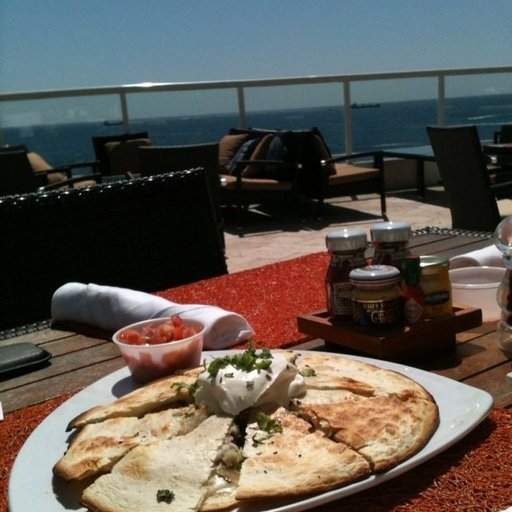

In [15]:
from random import randint

idx = randint(0, len(train_dataset) - 1)

print("Idx:", idx, ", Label:", train_dataset.features["label"].int2str(train_dataset[idx]["label"]))
train_dataset[idx]["image"]

In [ ]:
train_dataset.features["label"].int2str(train_dataset[0]["label"])

In [ ]:
dataset2 = load_dataset("ariG23498/flickr8k")
dataset2

In [ ]:
dataset_dict = dataset2["train"].train_test_split(test_size=0.15, seed=42)
ndataset_dict = dataset_dict["train"].train_test_split(test_size=0.1, seed=42)

train_dataset = ndataset_dict["train"]
validation_dataset = ndataset_dict["test"]
test_dataset = dataset_dict["test"]

dataset_dict = {
    "train": train_dataset,
    "validation": validation_dataset,
    "test": test_dataset
}
dataset_dict

In [ ]:
dataset2["train"].features

In [16]:
from datasets import Dataset

d = Dataset.from_csv("reviews_simple.csv")
d

Dataset({
    features: ['text', 'label'],
    num_rows: 4
})

In [ ]:
Dataset.from

In [17]:
d = load_dataset("csv", data_files="reviews_simple.csv")
d

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 4
    })
})

---
## Model Fine-tuning examples

#### A Skeletal example

In [18]:
import pandas as pd
from datasets import Dataset
from transformers import (
    AutoTokenizer, 
    AutoModelForSequenceClassification, 
    TrainingArguments, 
    Trainer,
    pipeline
)

# ==========================================
# 1. Prepare Your Custom Dataset
# ==========================================
# Sample dictionary (you can also load a CSV via pandas: pd.read_csv("data.csv"))
raw_data = {
    "text": [
        "I absolutely love this product! Highly recommended.",
        "Worst experience ever, totally disappointed.",
        "It's okay, nothing extraordinary.",
        "Great quality and fast delivery!",
        "Poor customer service and cheap quality.",
        "Fantastic service, will definitely buy again!"
    ],
    "label": [1, 0, 0, 1, 0, 1]  # 1: Positive, 0: Negative
}

# Convert dict to Hugging Face Dataset
#df = pd.DataFrame(raw_data)
dataset = Dataset.from_dict(raw_data)
dataset

Dataset({
    features: ['text', 'label'],
    num_rows: 6
})

In [19]:
# Split into train and test/validation sets
dataset_split = dataset.train_test_split(test_size=0.33, seed=42)
train_dataset = dataset_split["train"]
eval_dataset = dataset_split["test"]

print(train_dataset)
print(eval_dataset)

Dataset({
    features: ['text', 'label'],
    num_rows: 4
})
Dataset({
    features: ['text', 'label'],
    num_rows: 2
})


In [20]:

# ==========================================
# 2. Load Tokenizer & Model
# ==========================================
MODEL_NAME = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Define label mappings
id2label = {0: "NEGATIVE", 1: "POSITIVE"}
label2id = {"NEGATIVE": 0, "POSITIVE": 1}

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, 
    num_labels=2, 
    id2label=id2label, 
    label2id=label2id
)

# ==========================================
# 3. Tokenize Data
# ==========================================
def preprocess_function(examples):
    # Truncate and pad inputs to fit model context
    return tokenizer(examples["text"], truncation=True, max_length=128)

tokenized_train = train_dataset.map(preprocess_function, batched=True)
tokenized_eval = eval_dataset.map(preprocess_function, batched=True)

print(tokenized_train)
print(tokenized_eval)

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Map:   0%|          | 0/4 [00:00<?, ? examples/s]

Map:   0%|          | 0/2 [00:00<?, ? examples/s]

Dataset({
    features: ['text', 'label', 'input_ids', 'attention_mask'],
    num_rows: 4
})
Dataset({
    features: ['text', 'label', 'input_ids', 'attention_mask'],
    num_rows: 2
})


In [21]:
model

DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSdpaAttention(
            (dropout): Dropout(p=0.1, inplace=False)
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
          (ffn): FFN(
            (dropout): Dropout(p=0.1, inplace=False)


In [22]:
model.num_parameters(only_trainable=True), model.num_parameters()

(66955010, 66955010)

In [23]:
# For partial fine-tuning, freeze all parameters (across layers).
# Then, only unfreeze the last few layers as required.

# Freezing all parameters
for param in model.parameters():
    param.requires_grad = False  # Freeze all parameters

model.num_parameters(only_trainable=True), model.num_parameters()

(0, 66955010)

In [27]:
for name, parameter in model.named_parameters():
    print(name)

distilbert.embeddings.word_embeddings.weight
distilbert.embeddings.position_embeddings.weight
distilbert.embeddings.LayerNorm.weight
distilbert.embeddings.LayerNorm.bias
distilbert.transformer.layer.0.attention.q_lin.weight
distilbert.transformer.layer.0.attention.q_lin.bias
distilbert.transformer.layer.0.attention.k_lin.weight
distilbert.transformer.layer.0.attention.k_lin.bias
distilbert.transformer.layer.0.attention.v_lin.weight
distilbert.transformer.layer.0.attention.v_lin.bias
distilbert.transformer.layer.0.attention.out_lin.weight
distilbert.transformer.layer.0.attention.out_lin.bias
distilbert.transformer.layer.0.sa_layer_norm.weight
distilbert.transformer.layer.0.sa_layer_norm.bias
distilbert.transformer.layer.0.ffn.lin1.weight
distilbert.transformer.layer.0.ffn.lin1.bias
distilbert.transformer.layer.0.ffn.lin2.weight
distilbert.transformer.layer.0.ffn.lin2.bias
distilbert.transformer.layer.0.output_layer_norm.weight
distilbert.transformer.layer.0.output_layer_norm.bias
distil

In [28]:
# Unfreeze the last few layers.

for name, param in model.named_parameters():
    #if "layer.4" in name or "layer.5" in name:
    if "layer.5" in name:
        param.requires_grad = True  # Unfreeze last two layers

model.num_parameters(only_trainable=True), model.num_parameters()

(7087872, 66955010)

In [29]:
from transformers import Trainer, TrainingArguments
# ==========================================
# 4. Set Training Arguments & Trainer
# ==========================================
training_args = TrainingArguments(
    output_dir="../../data/custom_classification_model",
    eval_strategy="epoch",       # Evaluate at the end of every epoch
    save_strategy="epoch",       # Save checkpoint at the end of every epoch
    learning_rate=2e-5,
    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,
    num_train_epochs=30,
    weight_decay=0.01,
    logging_steps=1
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_eval,
    processing_class=tokenizer
)


In [30]:

# ==========================================
# 5. Fine-Tune & Save Model
# ==========================================
print("Starting training...")
trainer.train()


Starting training...


/opt/anaconda3/envs/hf4_env/lib/python3.11/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss
1,0.705600,0.687919
2,0.678700,0.685904
3,0.648400,0.683667
4,0.694400,0.681592
5,0.646800,0.679906
6,0.651700,0.677974
7,0.698100,0.676192
8,0.651500,0.674265
9,0.677600,0.672314
10,0.590500,0.670324


/opt/anaconda3/envs/hf4_env/lib/python3.11/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)
/opt/anaconda3/envs/hf4_env/lib/python3.11/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)
/opt/anaconda3/envs/hf4_env/lib/python3.11/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)
/opt/anaconda3/envs/hf4_env/lib/python3.11/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)
/opt/anaconda3/envs/hf4_env/lib/python3.11/site-packages

TrainOutput(global_step=60, training_loss=0.6055602639913559, metrics={'train_runtime': 14.9584, 'train_samples_per_second': 8.022, 'train_steps_per_second': 4.011, 'total_flos': 319784579568.0, 'train_loss': 0.6055602639913559, 'epoch': 30.0})

In [33]:

# Save final model and tokenizer locally
trainer.save_model("../../final_saved_model")
tokenizer.save_pretrained("../../final_saved_model")
print("Model saved successfully!")

# ==========================================
# 6. Test with Inference Pipeline
# ==========================================
classifier = pipeline("text-classification", model="../../final_saved_model")

test_text = "Worst experience using this service"
prediction = classifier(test_text)

print(f"\nText: {test_text}")
print(f"Prediction: {prediction}")

Device set to use mps:0


Model saved successfully!

Text: Worst experience using this service
Prediction: [{'label': 'NEGATIVE', 'score': 0.5530180335044861}]


#### Exercise: Try training the model using imdb / rottentomatoes / amazon product reviews datasets and check if the accuracy can be improved

---

#### Finetuning ModernBERT with custom dataset

In [34]:
from datasets import load_dataset

# Dataset id from huggingface.co/dataset
dataset_id = "cornell-movie-review-data/rotten_tomatoes"

# Load raw dataset
raw_dataset = load_dataset(dataset_id)

print(f"Train dataset size: {len(raw_dataset['train'])}")
print(f"Test dataset size: {len(raw_dataset['test'])}")

Train dataset size: 8530
Test dataset size: 1066


In [35]:
raw_dataset["train"].features

{'text': Value('string'), 'label': ClassLabel(names=['neg', 'pos'])}

In [49]:
from random import randrange

random_id = randrange(len(raw_dataset['train']))
raw_dataset['train'][random_id]


{'text': "this odd , poetic road movie , spiked by jolts of pop music , pretty much takes place in morton's ever-watchful gaze -- and it's a tribute to the actress , and to her inventive director , that the journey is such a mesmerizing one .",
 'label': 1}

In [50]:
from transformers import AutoTokenizer

# Model id to load the tokenizer
model_id = "answerdotai/ModernBERT-base"

# Load Tokenizer
tokenizer = AutoTokenizer.from_pretrained(model_id)
tokenizer.model_max_length = 512 # set model_max_length to 512 as prompts are not longer than 1024 tokens

# Tokenize helper function
def tokenize(batch):
    return tokenizer(batch['text'], padding='max_length', truncation=True, return_tensors="pt")

# Tokenize dataset
raw_dataset =  raw_dataset.rename_column("label", "labels") # to match Trainer
tokenized_dataset = raw_dataset.map(tokenize, batched=True,remove_columns=["text"])

print(tokenized_dataset["train"].features.keys())
# dict_keys(['input_ids', 'attention_mask','labels'])

dict_keys(['labels', 'input_ids', 'attention_mask'])


In [51]:
from transformers import AutoModelForSequenceClassification

# Model id to load the tokenizer
model_id = "answerdotai/ModernBERT-base"

# Prepare model labels - useful for inference
labels = tokenized_dataset["train"].features["labels"].names
num_labels = len(labels)
label2id, id2label = dict(), dict()
for i, label in enumerate(labels):
    label2id[label] = str(i)
    id2label[str(i)] = label

# Download the model from huggingface.co/models
model = AutoModelForSequenceClassification.from_pretrained(
    model_id, num_labels=num_labels, label2id=label2id, id2label=id2label,
)

Some weights of ModernBertForSequenceClassification were not initialized from the model checkpoint at answerdotai/ModernBERT-base and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [ ]:
!pip install scikit-learn

In [52]:
import numpy as np
from sklearn.metrics import f1_score

# Metric helper method
def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    predictions = np.argmax(predictions, axis=1)
    score = f1_score(
            labels, predictions, labels=labels, pos_label=1, average="weighted"
        )
    return {"f1": float(score) if score == 1 else score}

In [53]:
from transformers import Trainer, TrainingArguments

# Define training args
training_args = TrainingArguments(
    output_dir= "../../data/modernbert-rotten-tomatoes",
    per_device_train_batch_size=32,
    per_device_eval_batch_size=16,
    learning_rate=5e-5,
		num_train_epochs=5,
    bf16=True, # bfloat16 training 
    optim="adamw_torch_fused", # improved optimizer 
    # logging & evaluation strategies
    logging_strategy="steps",
    logging_steps=100,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    # push to hub parameters
    #report_to="tensorboard",
    push_to_hub=False,

)

# Create a Trainer instance
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["test"],
    compute_metrics=compute_metrics,
)

In [ ]:
# Start training
trainer.train()

/opt/anaconda3/envs/hf4_env/lib/python3.11/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss


In [ ]:
# Save processor and create model card
tokenizer.save_pretrained("modernbert-rotten-tomatoes")
trainer.create_model_card()
trainer.push_to_hub()

---

### Finetuning an Image Classifier (ViT) with custom Image dataset

#### The `Trainer` API

`Trainer` is a complete training and evaluation loop for Transformers’ PyTorch models. Plug a model, preprocessor, dataset, and training arguments into `Trainer` and let it handle the rest to start training faster.

The Trainer simplifies the overhead of implementing our training loop for our training workflow using PyTorch models.

Trainer contains all the necessary components of a training loop.

 1. calculate the loss from a training step
 2. calculate the gradients with the backward method
 3. update the weights based on the gradients
 4. repeat until the predetermined number of epochs is reached

Manually coding this training loop everytime can be inconvenient or a barrier if you’re just getting started with machine learning. Trainer abstracts this process, allowing you to focus on the model, dataset, and training design choices.

The training hyperparameters and options can be easily configured your using `TrainingArguments` which supports many features such as distributed training, torch.compile, mixed precision training, and saving the model to the Hub.

The `TrainingArguments` takes around *120* parameters for configuration!


#### Analyze the custom dataset (ChessMan)

This dataset can be downloaded from https://files.chandrashekar.info/chessman.zip


In [1]:
##### Step 1: Load your custom dataset

from datasets import load_dataset

dataset = load_dataset("../../data/Chessman-image-dataset/Chess")
dataset

Resolving data files:   0%|          | 0/553 [00:00<?, ?it/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 553
    })
})

In [8]:
dataset["train"].features["label"].num_classes

6

In [15]:
dataset["train"][200]

{'image': <PIL.Image.Image image mode=RGB size=884x1390>, 'label': 2}

In [9]:
dataset['train'].features["label"].names

['Bishop', 'King', 'Knight', 'Pawn', 'Queen', 'Rook']

In [ ]:
dataset["train"].features["label"].num_classes

In [16]:
dataset["train"].features["label"]

ClassLabel(names=['Bishop', 'King', 'Knight', 'Pawn', 'Queen', 'Rook'])

In [17]:
lbl = dataset["train"].features["label"]
lbl

ClassLabel(names=['Bishop', 'King', 'Knight', 'Pawn', 'Queen', 'Rook'])

In [22]:
lbl.str2int(["Queen", "Pawn", "King", "Bishop"])

[4, 3, 1, 0]

In [23]:
lbl.int2str([3, 2, 1, 1, 0])

['Pawn', 'Knight', 'King', 'King', 'Bishop']

In [2]:
##### Step 2: Split the dataset into training, validation and testing sets

# Split the dataset into training and testing sets
train_test = dataset["train"].train_test_split(test_size=0.2)
train_test


DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 442
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 111
    })
})

In [3]:

train_dataset = train_test["train"]
print(train_dataset)

# Further split the testing set into validation and testing sets
test_val = train_test["test"].train_test_split(test_size=0.5)
test_val

Dataset({
    features: ['image', 'label'],
    num_rows: 442
})


DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 55
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 56
    })
})

In [4]:
val_dataset = test_val["train"]
test_dataset = test_val["test"]

# Organize the datasets into a dictionary
from datasets import DatasetDict
dataset = DatasetDict({
    "train": train_dataset,
    "validation": val_dataset,
    "test": test_dataset
})
dataset

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 442
    })
    validation: Dataset({
        features: ['image', 'label'],
        num_rows: 55
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 56
    })
})

In [5]:
num_classes = dataset["train"].features["label"].num_classes
num_classes

6

In [6]:
##### Step 3: Use a pretrained model

checkpoint = "google/vit-base-patch16-224-in21k"

In [7]:
from transformers import AutoModelForImageClassification

model = AutoModelForImageClassification.from_pretrained(
    checkpoint, num_labels=num_classes
)
print(f"Total parameters: {model.num_parameters():,}")
print(f"Trainable parameters: {model.num_parameters(only_trainable=True):,}")

ImportError: huggingface-hub>=0.34.0,<1.0 is required for a normal functioning of this module, but found huggingface-hub==1.28.0.
Try: `pip install transformers -U` or `pip install -e '.[dev]'` if you're working with git main

In [32]:
##### For partial fine-tuning, freeze all layers except the last few

# First, freeze all parameters
for params in model.parameters():
    params.requires_grad = False  # Freeze all parameters

# Unfreeze the last layer and classifier for fine-tuning
for name, param in model.named_parameters():
    if "layer.11" in name or "layer.10" in name or "layer.9" in name or "classifier" in name:
        param.requires_grad = True  # Unfreeze last few layers and classifier

model.num_parameters(only_trainable=True), model.num_parameters()

(21268230, 85803270)

In [52]:
##### Step 4: Preprocess the images suited to the model

from transformers import AutoImageProcessor
image_processor = AutoImageProcessor.from_pretrained(checkpoint, use_fast=True)
image_processor

ViTImageProcessorFast {
  "crop_size": null,
  "data_format": "channels_first",
  "default_to_square": true,
  "device": null,
  "disable_grouping": null,
  "do_center_crop": null,
  "do_convert_rgb": null,
  "do_normalize": true,
  "do_pad": null,
  "do_rescale": true,
  "do_resize": true,
  "image_mean": [
    0.5,
    0.5,
    0.5
  ],
  "image_processor_type": "ViTImageProcessorFast",
  "image_std": [
    0.5,
    0.5,
    0.5
  ],
  "input_data_format": null,
  "pad_size": null,
  "resample": 2,
  "rescale_factor": 0.00392156862745098,
  "return_tensors": null,
  "size": {
    "height": 224,
    "width": 224
  }
}

In [ ]:
img = dataset["train"][0]["image"]
img


In [ ]:
import numpy as np
np.array(img).shape


In [ ]:
i2 = img.convert("RGB")
np.array(i2).shape

In [53]:
#### Implement the preprocess_function to convert images to RGB and tokenize them

def preprocess_function(examples):
    images = [image.convert("RGB") for image in examples["image"]]
    inputs = image_processor(images=images, return_tensors="pt")
    inputs["label"] = examples["label"]
    return inputs

result = preprocess_function(dataset["train"][:2])
list(result.keys())
result["pixel_values"]

tensor([[[[0.6078, 0.6157, 0.6235,  ..., 0.6078, 0.6078, 0.6078],
          [0.6235, 0.6314, 0.6392,  ..., 0.6157, 0.6078, 0.6157],
          [0.6314, 0.6392, 0.6392,  ..., 0.6157, 0.6078, 0.6157],
          ...,
          [0.8118, 0.8118, 0.8118,  ..., 0.7020, 0.7020, 0.6863],
          [0.8118, 0.8196, 0.8196,  ..., 0.7020, 0.7020, 0.6863],
          [0.8196, 0.8196, 0.8196,  ..., 0.7020, 0.7020, 0.6863]],

         [[0.5529, 0.5608, 0.5686,  ..., 0.5765, 0.5765, 0.5608],
          [0.5686, 0.5765, 0.5843,  ..., 0.5843, 0.5765, 0.5686],
          [0.5765, 0.5843, 0.5843,  ..., 0.5843, 0.5765, 0.5686],
          ...,
          [0.7098, 0.7098, 0.7098,  ..., 0.6000, 0.6000, 0.5843],
          [0.7098, 0.7176, 0.7176,  ..., 0.6000, 0.6000, 0.5843],
          [0.7176, 0.7176, 0.7176,  ..., 0.6000, 0.6000, 0.5843]],

         [[0.4745, 0.4824, 0.4902,  ..., 0.5529, 0.5529, 0.5608],
          [0.4902, 0.4980, 0.5059,  ..., 0.5608, 0.5529, 0.5608],
          [0.4980, 0.5059, 0.5059,  ..., 0

In [54]:
#### Process the entire dataset using the preprocess_function
prepared_dataset = dataset.map(preprocess_function, batched=True)
prepared_dataset

DatasetDict({
    train: Dataset({
        features: ['image', 'label', 'pixel_values'],
        num_rows: 442
    })
    validation: Dataset({
        features: ['image', 'label', 'pixel_values'],
        num_rows: 55
    })
    test: Dataset({
        features: ['image', 'label', 'pixel_values'],
        num_rows: 56
    })
})

In [36]:
dataset["train"][40]

{'image': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=250x274>,
 'label': 1}

In [37]:
prepared_dataset["train"][40]

{'image': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=250x274>,
 'label': 1,
 'pixel_values': [[[-0.4588235318660736,
    -0.4588235318660736,
    -0.4588235318660736,
    -0.4588235318660736,
    -0.4588235318660736,
    -0.4588235318660736,
    -0.4588235318660736,
    -0.4588235318660736,
    -0.4588235318660736,
    -0.4588235318660736,
    -0.4588235318660736,
    -0.4588235318660736,
    -0.4588235318660736,
    -0.4588235318660736,
    -0.4588235318660736,
    -0.4588235318660736,
    -0.4588235318660736,
    -0.4588235318660736,
    -0.4588235318660736,
    -0.4588235318660736,
    -0.4588235318660736,
    -0.4588235318660736,
    -0.4588235318660736,
    -0.4588235318660736,
    -0.4588235318660736,
    -0.4588235318660736,
    -0.4588235318660736,
    -0.4588235318660736,
    -0.4588235318660736,
    -0.4588235318660736,
    -0.4588235318660736,
    -0.4588235318660736,
    -0.4588235318660736,
    -0.4588235318660736,
    -0.4588235318660736,
    -0.45882353186607

In [38]:
##### Step 6: Define the training arguments and Trainer
from transformers import TrainingArguments, Trainer

training_args = TrainingArguments(
    output_dir="../../data/results",
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    dataloader_pin_memory=False # silence the warning on MacOS Apple Silicon
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=prepared_dataset["train"],
    eval_dataset=prepared_dataset["validation"],
)


In [39]:
##### Step 7: Inference / Predict using the test set
predictions = trainer.predict(prepared_dataset["test"])
predictions.metrics

{'test_loss': 1.8299006223678589,
 'test_model_preparation_time': 0.0015,
 'test_runtime': 2.8729,
 'test_samples_per_second': 19.492,
 'test_steps_per_second': 1.392}

In [ ]:
predictions.predictions

In [41]:
##### Step 8: Evaluate the model performance
import numpy as np
predicted_labels = np.argmax(predictions.predictions, axis=-1)
true_labels = predictions.label_ids
print(true_labels, predicted_labels, sep="\n")


[4 5 0 0 2 0 5 3 1 2 5 0 1 3 2 2 2 1 4 5 5 5 3 2 2 5 2 2 5 2 2 2 4 5 4 5 3
 4 2 4 1 5 5 0 5 3 3 1 0 4 3 1 3 4 3 1]
[2 2 2 3 1 1 1 1 2 1 1 2 2 2 0 1 1 2 2 1 1 2 0 2 1 1 2 1 2 2 0 3 2 1 2 2 1
 2 1 2 2 2 1 2 2 2 1 3 2 2 2 1 3 2 2 2]


In [42]:

incorrect_indices = np.where(true_labels != predicted_labels)[0]
incorrect_labels = predicted_labels[incorrect_indices]
true_labels_incorrect = true_labels[incorrect_indices]

print("Incorrectly classified sample indices:", incorrect_indices)
print("Predicted labels for incorrect samples:", incorrect_labels)
print("True labels for incorrect samples:", true_labels_incorrect)


Incorrectly classified sample indices: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 24
 25 27 28 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48 49 50
 53 54 55]
Predicted labels for incorrect samples: [2 2 2 3 1 1 1 1 2 1 1 2 2 2 0 1 1 2 2 1 1 2 0 1 1 1 2 0 3 2 1 2 2 1 2 1 2
 2 2 1 2 2 2 1 3 2 2 2 2 2 2]
True labels for incorrect samples: [4 5 0 0 2 0 5 3 1 2 5 0 1 3 2 2 2 1 4 5 5 5 3 2 5 2 5 2 2 4 5 4 5 3 4 2 4
 1 5 5 0 5 3 3 1 0 4 3 4 3 1]


In [ ]:
incorrect_label_names = dataset["test"].features["label"].int2str(incorrect_labels)
true_label_names_incorrect = dataset["test"].features["label"].int2str(true_labels_incorrect)
print("Predicted label names for incorrect samples:", incorrect_label_names)
print("True label names for incorrect samples:", true_label_names_incorrect)

In [ ]:
incorrect_samples = dataset["test"].select(incorrect_indices)
incorrect_samples

In [ ]:
!conda install seaborn -y

In [ ]:
!conda install -c conda-forge scikit-learn -y

In [ ]:
!conda install matplotlib -y

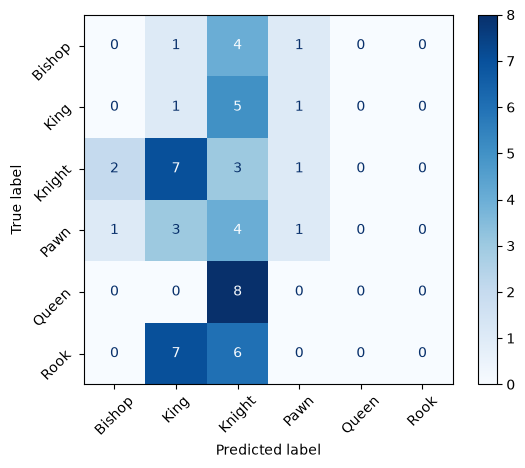

In [44]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

predictions = trainer.predict(prepared_dataset["test"])
y_pred = np.argmax(predictions.predictions, axis=1)
y_true = predictions.label_ids
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap=plt.cm.Blues)
disp.ax_.set_xticklabels(dataset["test"].features["label"].names, rotation=45)
disp.ax_.set_yticklabels(dataset["test"].features["label"].names, rotation=45)
plt.show()

#import seaborn as sns

#cm = confusion_matrix(true_labels, predicted_labels)
#label_names = dataset["train"].features["label"].names

#plt.figure(figsize=(10, 8))
#sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
#            xticklabels=label_names, yticklabels=label_names)

#plt.xlabel('Predicted Label')   
#plt.ylabel('True Label')
#plt.title('Confusion Matrix')
#plt.show()

In [ ]:
import sklearn
sklearn.__version__

### Fine-tuning this model

In [ ]:
import evaluate


In [55]:
##### Define the evaluation metric
import numpy as np
import evaluate

metric = evaluate.load("accuracy")
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return metric.compute(predictions=predictions, 
                          references=labels)

In [56]:
##### Training the model with new dataset (fine-tuning)
import os
#os.environ["TENSORBOAD_LOGGING_DIR"] = "../../data/logs/vit-finetuned-chessman2"

from transformers import TrainingArguments, Trainer
training_args = TrainingArguments(
    output_dir="../../data/models/vit-finetuned-chessman-aug2",
    
    num_train_epochs=100,
    
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    
    weight_decay=0.01,
    
    logging_dir="../../data/logs/vit-finetuned-chessman-aug2",
    logging_strategy="epoch",

    eval_strategy="epoch", # evaluate every epoch, alternative to "steps"
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    greater_is_better=True,

    push_to_hub=False,    
    dataloader_pin_memory=False  # silence the warning on MacOS Apple Silicon
)

from transformers import EarlyStoppingCallback
early_stopping_callback = EarlyStoppingCallback(
    early_stopping_patience=3,  
    early_stopping_threshold=0.01
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=prepared_dataset["train"],
    eval_dataset=prepared_dataset["validation"],
    compute_metrics=compute_metrics,
    callbacks=[early_stopping_callback]
)
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy
1,1.583800,1.405285,0.618182
2,0.974900,0.835535,0.854545
3,0.497100,0.518293,0.927273
4,0.239300,0.369356,0.927273
5,0.144100,0.321432,0.927273
6,0.108000,0.309414,0.927273


TrainOutput(global_step=168, training_loss=0.5911934631211417, metrics={'train_runtime': 262.4251, 'train_samples_per_second': 168.429, 'train_steps_per_second': 10.67, 'total_flos': 2.0551612409782272e+17, 'train_loss': 0.5911934631211417, 'epoch': 6.0})

In [ ]:

trainer.save_model("../../data/models/vit-finetuned-chessman5")

In [57]:
predictions = trainer.predict(prepared_dataset["test"])
predictions.metrics


{'test_loss': 0.4525245726108551,
 'test_accuracy': 0.9642857142857143,
 'test_runtime': 2.4358,
 'test_samples_per_second': 22.99,
 'test_steps_per_second': 1.642}

In [58]:
import numpy as np
predicted_labels = np.argmax(predictions.predictions, axis=-1)
true_labels = predictions.label_ids
print(true_labels, predicted_labels, sep="\n")

[4 5 0 0 2 0 5 3 1 2 5 0 1 3 2 2 2 1 4 5 5 5 3 2 2 5 2 2 5 2 2 2 4 5 4 5 3
 4 2 4 1 5 5 0 5 3 3 1 0 4 3 1 3 4 3 1]
[4 5 0 0 2 0 5 3 1 2 5 0 1 3 2 2 2 1 4 5 5 5 2 2 2 5 2 2 5 2 2 2 4 5 4 5 3
 4 2 4 1 5 5 0 5 3 3 1 4 4 3 1 3 4 3 1]


In [59]:
incorrect_indices = np.where(true_labels != predicted_labels)[0]
incorrect_labels = predicted_labels[incorrect_indices]
true_labels_incorrect = true_labels[incorrect_indices]

true_label_names = dataset["test"].features["label"]

print("Incorrectly classified sample indices:", incorrect_indices)
print("Predicted labels for incorrect samples:", incorrect_labels)
print("True labels for incorrect samples:", true_labels_incorrect)

incorrect_label_names = dataset["test"].features["label"].int2str(incorrect_labels)
true_label_names_incorrect = dataset["test"].features["label"].int2str(true_labels_incorrect)
print("Predicted label names for incorrect samples:", incorrect_label_names)
print("True label names for incorrect samples:", true_label_names_incorrect)

Incorrectly classified sample indices: [22 48]
Predicted labels for incorrect samples: [2 4]
True labels for incorrect samples: [3 0]
Predicted label names for incorrect samples: ['Knight', 'Queen']
True label names for incorrect samples: ['Pawn', 'Bishop']


In [62]:
incorrect_samples = dataset["test"].select(incorrect_indices)
incorrect_samples

Dataset({
    features: ['image', 'label'],
    num_rows: 2
})

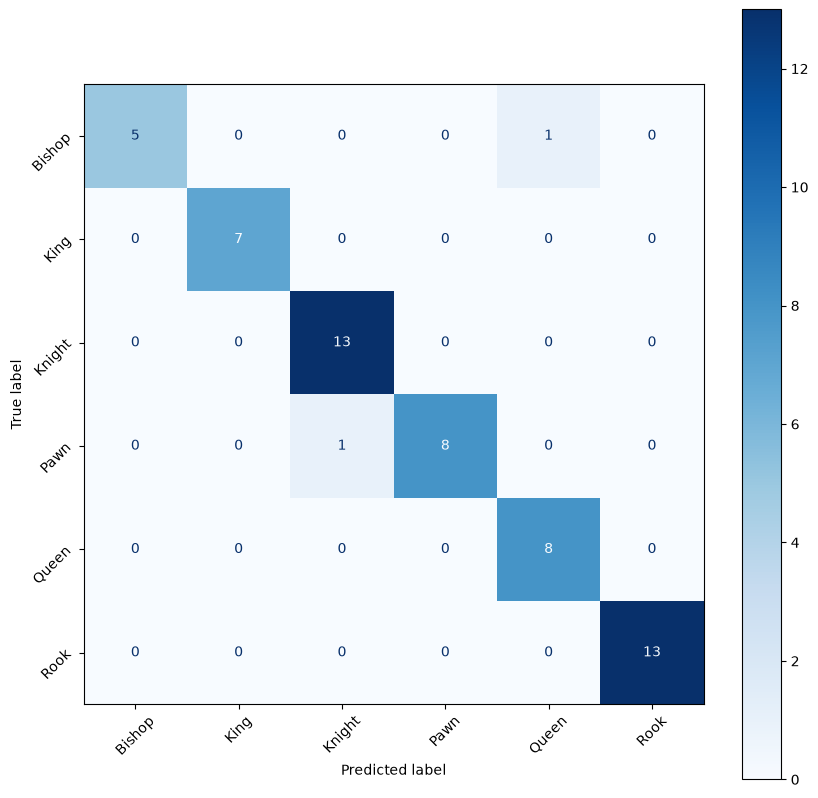

In [60]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
def plot_confusion_matrix(labels, pred_labels):

    fig = plt.figure(figsize=(10, 10))
    ax = fig.add_subplot(1, 1, 1)
    cm = confusion_matrix(labels, pred_labels)
    cm = ConfusionMatrixDisplay(cm, display_labels=range(6))
    cm.plot(values_format='d', cmap='Blues', ax=ax)
    cm.ax_.set_xticklabels(dataset["test"].features["label"].names, rotation=45)
    cm.ax_.set_yticklabels(dataset["test"].features["label"].names, rotation=45)
    plt.show()

plot_confusion_matrix(true_labels, predicted_labels)

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(true_labels, predicted_labels)
label_names = dataset["train"].features["label"].names

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_names, yticklabels=label_names)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
trainer.save_model("../../data/models/vit-finetuned-chessman-final2")

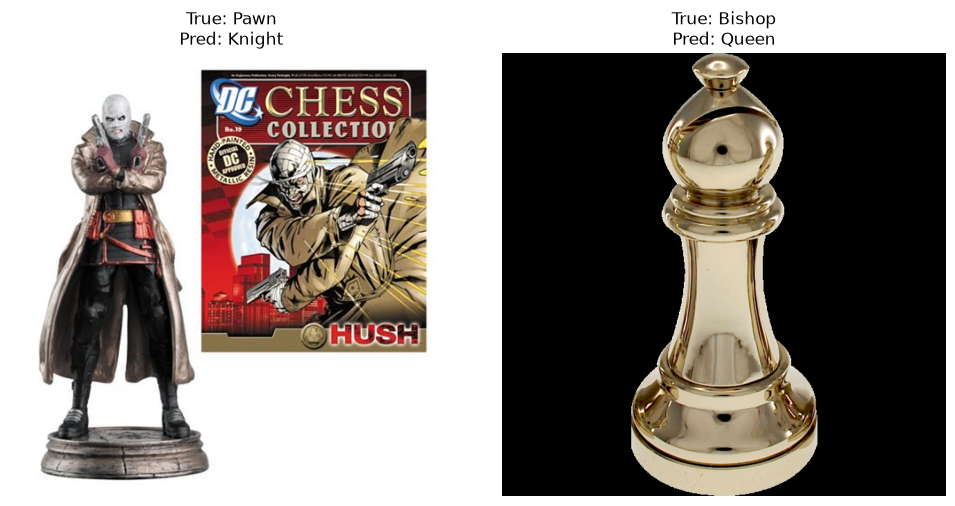

In [63]:
import matplotlib.pyplot as plt

num_plots = min(5, len(incorrect_samples))

plt.figure(figsize=(10, 5))
for i in range(num_plots):
    idx = incorrect_indices[i]
    # Assuming the dataset returns a dictionary with 'image' and 'label'
    sample = test_dataset[idx] 
    image = sample['image'] 
    
    plt.subplot(1, num_plots, i + 1)
    plt.imshow(image)
    plt.title(f"True: {true_label_names_incorrect[i]}\nPred: {incorrect_label_names[i]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

In [83]:
test_dataset.add_column(name="Queen", column=Image.open("../../data/chess_queen.jpeg"))

Flattening the indices:   0%|          | 0/56 [00:00<?, ? examples/s]

ValueError: Failed to concatenate on axis=1 because tables don't have the same number of rows

In [ ]:
from datasets import Dataset, DatasetDict
from PIL import Image
t_dataset = Dataset.from_dict({
    "image": [Image.open("../../data/chess_queen.jpeg")],
    "label": [lbl.str2int("Queen")]
})
t_dataset = DatasetDict({"test": t_dataset})
t_dataset 

DatasetDict({
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 1
    })
})

In [74]:
t_prep = t_dataset.map(preprocess_function)
t_prep

Map:   0%|          | 0/1 [00:00<?, ? examples/s]

TypeError: 'JpegImageFile' object is not iterable

---

### Exercise: Try fine-tuning ViT model for fatigue dataset (from Kaggle)
The link to the dataset: https://www.kaggle.com/datasets/rihabkaci99/fatigue-dataset/

Try using `mo-thecreator/vit-Facial-Expression-Recognition` and `trpakov/vit-face-expression` models 
from HuggingFace as the initial checkpoint

In [64]:
ls ../../data/Human_Face_Expression_Fatigue/

Fatigue/    NonFatigue/


In [ ]:
#### Step 1: Load your custom dataset
from datasets import load_dataset
dataset = load_dataset("../data/Human_Face_Expression_Fatigue")
dataset

In [ ]:
#### Step 2: Split the dataset into training, validation and testing sets
train_test = dataset["train"].train_test_split(test_size=0.2)
train_dataset = train_test["train"]
print(train_dataset)

test_val = train_test["test"].train_test_split(test_size=0.5)
val_dataset = test_val["train"]
test_dataset = test_val["test"]

from datasets import DatasetDict
dataset = DatasetDict({
    "train": train_dataset,
    "validation": val_dataset,
    "test": test_dataset
})
dataset

num_classes = dataset["train"].features["label"].num_classes
num_classes


In [ ]:
#### Step 3: Use a pretrained model
checkpoint = "mo-thecreator/vit-Facial-Expression-Recognition"
model = AutoModelForImageClassification.from_pretrained(
    checkpoint, 
    num_labels=num_classes,
    ignore_mismatched_sizes=True
)

In [ ]:
##### Step 4: Preprocess the images suited to the model
from transformers import AutoImageProcessor
image_processor = AutoImageProcessor.from_pretrained(checkpoint, use_fast=True)

def preprocess_function(examples):
    images = [image.convert("RGB") for image in examples["image"]]
    inputs = image_processor(images=images, return_tensors="pt")
    inputs["label"] = examples["label"]
    return inputs

prepared_dataset = dataset.map(preprocess_function, batched=True)
prepared_dataset

In [ ]:
##### Step 5: Setup evaluation metrics and callbacks (optional)
##### Define the evaluation metric
import numpy as np
import evaluate

metric = evaluate.load("accuracy")
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return metric.compute(predictions=predictions, 
                          references=labels)

In [ ]:
##### Step 6: Initialize the Trainer and define the training arguments, train the model
import os
os.environ["TENSORBOARD_LOGGING_DIR"] = "../data/logs/vit-facial-expression-fatigue"

from transformers import TrainingArguments, Trainer
training_args = TrainingArguments(
    output_dir="../data/vit-facial-expression-fatigue",
    
    num_train_epochs=100,
    
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    
    weight_decay=0.01,
    
    #logging_dir="../../data/logs/vit-facial-expression-fatigue",
    logging_strategy="epoch",

    eval_strategy="epoch", # evaluate every epoch, alternative to "steps"
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    greater_is_better=True,

    push_to_hub=False,    
    dataloader_pin_memory=False  # silence the warning on MacOS Apple Silicon
)

from transformers import EarlyStoppingCallback
early_stopping_callback = EarlyStoppingCallback(
    early_stopping_patience=3,  
    early_stopping_threshold=0.01
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=prepared_dataset["train"],
    eval_dataset=prepared_dataset["validation"],
    compute_metrics=compute_metrics,
    callbacks=[early_stopping_callback]
)
trainer.train()

In [ ]:
##### Step 7: Inference / Predict using the test set
predictions = trainer.predict(prepared_dataset["test"])
predictions.metrics


In [ ]:
##### Step 8: Evaluate the model performance with test set and visualize the results

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

import numpy as np
predicted_labels = np.argmax(predictions.predictions, axis=-1)
true_labels = predictions.label_ids
print(true_labels, predicted_labels, sep="\n")

cm = confusion_matrix(true_labels, predicted_labels)
label_names = prepared_dataset["train"].features["label"].names

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_names, yticklabels=label_names)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()


In [ ]:
#### Step 9: Save the fine-tuned model
trainer.save_model("../data/models/vit-finetuned-human-face-expression-fatigue")

In [ ]:
%load_ext tensorboard

In [ ]:
%tensorboard --logdir ../data/logs/vit-facial-expression-fatigue

---

In [ ]:
g = model.parameters()

In [ ]:
model.get_memory_footprint() / (1024 * 1024)

In [ ]:
total = 0
for p in model.parameters():
    total += p.numel()

total / (1000 * 1000)

---